# TP 4 – From an error on a sample to a PAC-Bayesian guarantee – Solutions

Fourth of five practical sessions (1: protocol, 2: bagging, 3: boosting, 4 and 5: PAC-Bayes). This session follows Sections 13 and 14 of the lecture notes, step by step. On a toy problem in which every true risk is known exactly, so that we can draw thousands of samples and *count* how often a bound fails, we (1) certify one classifier fixed in advance with Hoeffding's inequality and with the sharper kl bound, (2) see what goes wrong when the classifier is chosen with the sample and repair it with the union bound, (3) spread the confidence over the classifiers with a *prior* (Occam's bound), and then move from one classifier to a *distribution* over classifiers: (4) the KL divergence, (5) the first PAC-Bayesian bound of the notes, with its parameter $\lambda$, and the bounds of McAllester and Seeger used in practice, (6) the Gibbs posterior, and (7) a check that all these bounds hold. Majority votes are the subject of TP 5. The session lasts **three hours**; Part 8 contains the difficult questions. All the numbers and figures of these solutions are produced by the code of this notebook (one function per part, about one minute in total). Unless stated otherwise, $\delta=0.05$.

*Statistical Supervised Machine Learning – Master MIASHS & MALIA. Run the cells in order, from the folder of this notebook (it uses `../common` and `../data`). Each part: the statement, the code, then the solutions with the tables and figures produced by the code.*

**The toy problem.** The input $X$ is uniform on $[0,1]$. The clean label is $\operatorname{sign}(X-\theta^\star)$ with $\theta^\star=0.37$, and it is flipped with probability $\eta=0.15$. The class $\mathcal{H}$ contains the $K=102$ threshold classifiers $h_{t,s}(x)=s\cdot\operatorname{sign}(x-t)$, $t\in\{0,0.02,\dots,1\}$, $s\in\{-1,+1\}$. Unless stated otherwise, $\delta=0.05$.

1.  Show that $R_{\mathcal{D}}(h_{t,+1})=\eta+(1-2\eta)|t-\theta^\star|$ and $R_{\mathcal{D}}(h_{t,-1})=1-R_{\mathcal{D}}(h_{t,+1})$.\
    What is the best classifier of $\mathcal{H}$?

2.  Write `sample(m, rng)` and a *vectorized* function `emp_risks(x, y)` returning the $102$ empirical risks (build the $102\times m$ matrix of predictions).

## Setup

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
sys.path.insert(0, os.path.join(HERE, "..", "common"))
from tptools import kl, kl_inv_upper, hoeffding_width, show_table as _show_rows

DELTA = 0.05
C1, C2, C3, C4, C5, GREY = "#1f5f99", "#c8553d", "#2a9d8f", "#e9a13b", "#6c4f9c", "#8c8c8c"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.bbox": "tight", "figure.dpi": 120})

# column headers of the tables
HEADERS = {
    'p1_klinv': ['$q$', '$\\varepsilon$', 'my bisection', '`kl_inv_upper`'],
    'p1_coverage': ['$m$', 'mean $\\widehat{R}_S(h)$', 'mean test-set bound', 'coverage', 'mean kl bound', 'coverage'],
    'p1_widths': ['observed error', 'test-set width', 'kl width'],
    'p2_erm': ['$m$', 'mean gap', '(a) as if fixed', '(b) union, ERM', '(c) union, all $h$'],
    'p3_occam': ['prior', 'ERM – bound', 'ERM – true risk', 'bound minimizer – bound', 'bound minimizer – true risk', 'coverage (all $h$)'],
    'p4_posteriors': ['posterior $Q$', '$\\widehat{R}_S(G_Q)$', '$\\operatorname{KL}(Q\\Vert P)$', '$R_{\\mathcal{D}}(G_Q)$'],
    'p5_linear': ['posterior $Q$', '$\\lambda=10$', '$\\lambda=30$', '$\\lambda=100$', '$\\lambda=300$', '$\\lambda^\\star$ (not allowed)', 'best of the grid, $\\ln\\frac4\\delta$'],
    'p5_all': ['posterior $Q$', 'Theorem 14.4, grid', 'McAllester', 'Seeger', '$R_{\\mathcal{D}}(G_Q)$'],
    'p6_gibbs': ['$\\lambda$', '$\\widehat{R}_S(G_{Q_\\lambda})$', '$\\operatorname{KL}(Q_\\lambda\\Vert P)$', "Seeger's bound", '$R_{\\mathcal{D}}(G_{Q_\\lambda})$'],
    'p7_coverage': ['$m$', '$\\widehat{R}_S(G_Q)$', '$R_{\\mathcal{D}}(G_Q)$', "Seeger's bound", 'coverage', 'Theorem 14.4 (grid)', 'coverage', "ERM – Occam's bound", 'ERM – $R_{\\mathcal{D}}(\\hat h)$'],
}

TABLES, FIGURES = {}, {}


def keep_table(name, rows):
    """Keep the rows of a table ('a & b & c', math between $) to show it later with show_table(name)."""
    TABLES[name] = rows


def keep_figure(fig, name):
    """Keep a figure to show it later with show_figure(name)."""
    FIGURES[name] = fig
    plt.close(fig)


def show_table(name):
    _show_rows(TABLES[name], HEADERS.get(name))


def show_figure(name):
    from IPython.display import display
    display(FIGURES[name])

### The toy problem: thresholds on [0,1] with label noise (all true risks are known)

In [2]:
THETA, ETA = 0.37, 0.15
T = np.round(np.arange(0, 1.0001, 0.02), 2)                  # 51 thresholds
TT = np.r_[T, T]; SS = np.r_[np.ones(51), -np.ones(51)]       # the 102 classifiers h_{t,s}(x) = s sign(x - t)
K = len(TT)
PRIOR = np.ones(K) / K


def true_risks():
    r = ETA + (1 - 2 * ETA) * np.abs(TT - THETA)
    return np.where(SS > 0, r, 1 - r)


def sample(m, rng):
    x = rng.rand(m); y = np.where(x > THETA, 1, -1)
    return x, y * np.where(rng.rand(m) < ETA, -1, 1)


def emp_risks(x, y):
    """Empirical risks of the 102 classifiers (vectorized)."""
    pred = SS[:, None] * np.where(x[None, :] > TT[:, None], 1, -1)
    return np.mean(pred != y[None, :], axis=1)


def KL(Q, P):
    """KL divergence between two distributions on a finite set (0 ln 0 = 0)."""
    nz = Q > 0
    return float(np.sum(Q[nz] * np.log(Q[nz] / P[nz])))


def linear_bound(gibbs_emp, kl_qp, m, lam, delta=DELTA):
    """Theorem 14.4: R(G_Q) <= R_S(G_Q) + (KL + ln(1/delta)) / lam + lam / (8m), lam fixed in advance."""
    return gibbs_emp + (kl_qp + np.log(1 / delta)) / lam + lam / (8 * m)


def mcallester(gibbs_emp, kl_qp, m, delta=DELTA):
    return gibbs_emp + np.sqrt((kl_qp + np.log(2 * np.sqrt(m) / delta)) / (2 * m))


def seeger(gibbs_emp, kl_qp, m, delta=DELTA):
    return kl_inv_upper(gibbs_emp, (kl_qp + np.log(2 * np.sqrt(m) / delta)) / m)


def gibbs_posterior(r, lam, P=PRIOR):
    """Proposition 14.6: Q_lambda(h) proportional to P(h) exp(-lambda r(h))."""
    a = np.log(P) - lam * r; a -= a.max(); Q = np.exp(a)
    return Q / Q.sum()

### Solution

**1.** $h_{t,+1}$ disagrees with the clean label exactly on the interval between $t$ and $\theta^\star$, of probability $|t-\theta^\star|$. There it errs when the label is not flipped (probability $1-\eta$), elsewhere when it is flipped: $R_{\mathcal{D}}(h_{t,+1})=(1-\eta)|t-\theta^\star|+\eta(1-|t-\theta^\star|)=\eta+(1-2\eta)|t-\theta^\star|$, and $h_{t,-1}=-h_{t,+1}$ errs exactly where $h_{t,+1}$ is right. The best classifiers of $\mathcal{H}$ are $h_{0.36,+1}$ and $h_{0.38,+1}$, with risk $0.15+0.7\times0.01=0.157$ (the Bayes risk is $\eta=0.15$).

**2.** With `TT`, `SS` the vectors of thresholds and signs: `pred = SS[:, None] * np.where(x[None, :] > TT[:, None], 1, -1)`, then the row means of `pred != y[None, :]` (see the cell above). The functions `linear_bound`, `mcallester`, `seeger` and `gibbs_posterior` of the same cell are used from Part 5 on.

## Part 1 – One classifier fixed in advance: Hoeffding and kl bounds (Sections 13.1–13.4)

Fix $h=h_{0.6,+1}$, whose risk is $p=R_{\mathcal{D}}(h)=0.311$. For a sample of size $m$, $m\widehat{R}_{S}(h)\sim\mathcal B(m,p)$: you can simulate $\widehat{R}_{S}(h)$ directly with `rng.binomial`.

1.  **Test-set bound.** From Hoeffding's inequality (Theorem 13.2), $\mathbb{P}\big(R_{\mathcal{D}}(h)-\widehat{R}_{S}(h)\geq\varepsilon\big)\leq e^{-2m\varepsilon^2}$, prove Corollary 13.3: with probability at least $1-\delta$, $R_{\mathcal{D}}(h)\leq\widehat{R}_{S}(h)+\sqrt{\ln(1/\delta)/(2m)}$.\
    Why must $h$ be fixed before the sample is drawn?

2.  **kl bound.** Theorem 13.5 gives, with probability at least $1-\delta$, $R_{\mathcal{D}}(h)\leq\overline{\operatorname{kl}}^{-1}\big(\widehat{R}_{S}(h),\ln(1/\delta)/m\big)$, where $\overline{\operatorname{kl}}^{-1}(q,\varepsilon)=\max\{p\in[q,1]:\operatorname{kl}(q\|p)\leq\varepsilon\}$ and $\operatorname{kl}(q\|p)=q\ln\frac qp+(1-q)\ln\frac{1-q}{1-p}$ (Definition 13.4).\
    Implement $\overline{\operatorname{kl}}^{-1}$ by bisection (Algorithm 12), for whole arrays of $q$ at once, and check it against `kl_inv_upper` of `common/tptools.py`; check that $\overline{\operatorname{kl}}^{-1}(0.1,0.05)\approx0.220$ (example of Section 13.4).\
    Using Pinsker's inequality $\operatorname{kl}(q\|p)\geq2(q-p)^2$, show that the kl bound is never worse than the test-set bound.

3.  For $m\in\{50,100,500,2000\}$, draw $10\,000$ samples and compute the mean of each bound and its *coverage* (the proportion of samples for which $R_{\mathcal{D}}(h)$ is below the bound).\
    Comment.

4.  For $m=100$, plot the width "bound $-\widehat{R}_{S}(h)$" of both bounds as a function of the observed error $\widehat{R}_{S}(h)\in[0,0.5]$.\
    When is the kl bound much better?

In [3]:
def kl_inv_bisection(q, eps, n_iter=60):
    """Algorithm 12 of the notes, vectorized: the answer is in [a, b], halve the interval n_iter times."""
    q, eps = np.broadcast_arrays(np.asarray(q, float), np.asarray(eps, float))
    a, b = q.copy(), np.ones_like(q)
    for _ in range(n_iter):
        c = (a + b) / 2
        too_far = kl(q, c) > eps
        b = np.where(too_far, c, b); a = np.where(too_far, a, c)
    return b


def part1():
    print("Part 1")
    keep_table("p1_klinv", [f"{q} & {e} & {float(kl_inv_bisection(q, e)):.4f} & {kl_inv_upper(q, e):.4f}"
                            for q, e in [(0.1, 0.05), (0.0, 0.03), (0.3, 0.01), (0.5, 0.2)]])
    R = true_risks(); i = int(np.where((TT == 0.6) & (SS > 0))[0][0]); p = R[i]
    rng = np.random.RandomState(0); N = 10000; rows = []
    for m in [50, 100, 500, 2000]:
        q = rng.binomial(m, p, size=N) / m
        hb = q + hoeffding_width(m, DELTA); kb = kl_inv_bisection(q, np.log(1 / DELTA) / m)
        rows.append(f"{m} & {np.mean(q):.3f} & {np.mean(hb):.3f} & {np.mean(p <= hb):.4f} & {np.mean(kb):.3f} & {np.mean(p <= kb):.4f}")
    keep_table("p1_coverage", rows); print(f"   R(h) = {p:.3f}")
    qs = np.linspace(0, 0.5, 101); m = 100
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    ax.plot(qs, np.full_like(qs, hoeffding_width(m, DELTA)), color=C2, label="test-set bound (Hoeffding)")
    ax.plot(qs, kl_inv_bisection(qs, np.log(1 / DELTA) / m) - qs, color=C1, label="kl bound")
    ax.set_xlabel(r"observed error $\hat R_S(h)$"); ax.set_ylabel("bound $-$ observed error")
    ax.set_title(r"width of the upper bound, $m=100$, $\delta=0.05$", fontsize=9); ax.legend(fontsize=7.5)
    fig.tight_layout(); keep_figure(fig, "tp4_widths")
    keep_table("p1_widths", [f"{q:.2f} & {hoeffding_width(m, DELTA):.3f} & {float(kl_inv_bisection(q, np.log(1 / DELTA) / m)) - q:.3f}"
                             for q in [0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5]])

In [4]:
part1()

Part 1
   R(h) = 0.311


### Solution

**1.** Set $\varepsilon=\sqrt{\ln(1/\delta)/(2m)}$, so that $e^{-2m\varepsilon^2}=\delta$. The event $\{R_{\mathcal{D}}(h)-\widehat{R}_{S}(h)\geq\varepsilon\}$ has probability at most $\delta$; its complement, which is the claimed inequality, has probability at least $1-\delta$. Hoeffding's inequality applies to the losses $Z_i=\mathbb{1}\left[h(x_i)\neq y_i\right]$ only if they are independent with mean $R_{\mathcal{D}}(h)$: this holds if $h$ is *fixed* before the sample is drawn. If $h$ is chosen with the sample, the $Z_i$ depend on the whole sample and the argument breaks down (Part 2).

**2.** Our bisection (Algorithm 12) and the function of `tptools`:

In [5]:
show_table("p1_klinv")

| $q$ | $\varepsilon$ | my bisection | `kl_inv_upper` |
|:---:|:---:|:---:|:---:|
| 0.1 | 0.05 | 0.2201 | 0.2201 |
| 0.0 | 0.03 | 0.0296 | 0.0296 |
| 0.3 | 0.01 | 0.3672 | 0.3672 |
| 0.5 | 0.2 | 0.7871 | 0.7871 |

They agree, and $\overline{\operatorname{kl}}^{-1}(0.1,0.05)\approx0.220$ as in the notes. Comparison with the test-set bound: let $p_{\operatorname{kl}}=\overline{\operatorname{kl}}^{-1}(\hat q,\varepsilon)$ and $p_H=\hat q+\sqrt{\varepsilon/2}$ with $\varepsilon=\ln(1/\delta)/m$. By Pinsker, $\operatorname{kl}(\hat q\|p_H)\geq2(p_H-\hat q)^2=\varepsilon$, and $\operatorname{kl}(\hat q\|\cdot)$ is increasing on $[\hat q,1]$, so every $p>p_H$ has $\operatorname{kl}(\hat q\|p)>\varepsilon$: the maximum $p_{\operatorname{kl}}$ is at most $p_H$.

**3.** Mean of $\widehat{R}_{S}(h)$, mean bound and coverage over $10\,000$ samples:

In [6]:
show_table("p1_coverage")

| $m$ | mean $\widehat{R}_S(h)$ | mean test-set bound | coverage | mean kl bound | coverage |
|:---:|:---:|:---:|:---:|:---:|:---:|
| 50 | 0.310 | 0.483 | 0.9982 | 0.479 | 0.9865 |
| 100 | 0.311 | 0.434 | 0.9984 | 0.430 | 0.9927 |
| 500 | 0.311 | 0.366 | 0.9955 | 0.363 | 0.9917 |
| 2000 | 0.311 | 0.338 | 0.9966 | 0.337 | 0.9932 |

Both bounds hold in more than $95\%$ of the samples, as guaranteed (they are slightly conservative: the coverage is $98.6$ to $99.8\%$). The width decreases as $1/\sqrt m$: from $0.17$ for $m=50$ to $0.027$ for $m=2000$. For an error around $0.3$ the two bounds are almost equal.

**4.**

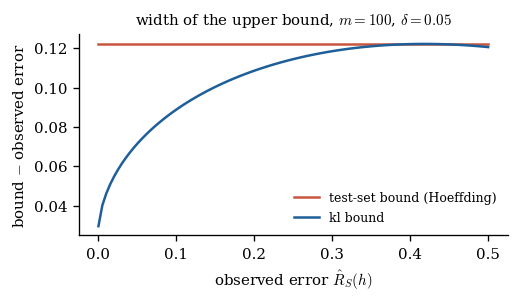

In [7]:
show_figure("tp4_widths")

In [8]:
show_table("p1_widths")

| observed error | test-set width | kl width |
|:---:|:---:|:---:|
| 0.00 | 0.122 | 0.030 |
| 0.02 | 0.122 | 0.055 |
| 0.05 | 0.122 | 0.072 |
| 0.10 | 0.122 | 0.089 |
| 0.20 | 0.122 | 0.109 |
| 0.30 | 0.122 | 0.118 |
| 0.50 | 0.122 | 0.121 |

The width of the test-set bound does not depend on the observed error ($0.122$ for $m=100$), because Hoeffding's inequality only uses the fact that the losses are in $[0,1]$. The kl bound adapts to the variance $p(1-p)$ of the Bernoulli variables: when the observed error is small it is much tighter ($0.030$ instead of $0.122$ for an observed error of $0$, a rate $\ln(1/\delta)/m$ instead of $\sqrt{\ln(1/\delta)/m}$). For good classifiers, always use the kl bound (Section 13.4).

## Part 2 – What goes wrong when we choose: the union bound (Section 13.5)

1.  Using the union bound (Lemma 13.6), prove Theorem 13.7: with probability at least $1-\delta$, *for all* $k\leq K$ simultaneously, $R_{\mathcal{D}}(h_k)\leq\widehat{R}_{S}(h_k)+\sqrt{\ln(K/\delta)/(2m)}$; give its kl version $R_{\mathcal{D}}(h_k)\leq\overline{\operatorname{kl}}^{-1}\big(\widehat{R}_{S}(h_k),\ln(K/\delta)/m\big)$.\
    Why does it hold for a classifier *selected* on the sample, whatever the selection rule?

2.  For $m\in\{50,100,400\}$ and $5000$ samples, select the empirical risk minimizer (ERM) $\hat h$ among the $102$ thresholds.\
    Compute the mean of $R_{\mathcal{D}}(\hat h)-\widehat{R}_{S}(\hat h)$, and the coverage of (a) the test-set bound with $\delta$ (as if $\hat h$ were fixed), (b) the union bound for $\hat h$, (c) the union bound for *all* the classifiers at once.\
    Comment.

In [9]:
def part2():
    print("Part 2")
    R = true_risks(); rng = np.random.RandomState(4); rows = []
    for m in [50, 100, 400]:
        gaps, cov_n, cov_u, cov_all = [], [], [], []
        for _ in range(5000):
            x, y = sample(m, rng); r = emp_risks(x, y); j = int(np.argmin(r))
            gaps.append(R[j] - r[j])
            cov_n.append(R[j] <= r[j] + hoeffding_width(m, DELTA))
            cov_u.append(R[j] <= r[j] + hoeffding_width(m, DELTA / K))
            cov_all.append(np.all(R <= r + hoeffding_width(m, DELTA / K)))
        rows.append(f"{m} & {np.mean(gaps):.3f} & {np.mean(cov_n):.3f} & {np.mean(cov_u):.4f} & {np.mean(cov_all):.4f}")
    keep_table("p2_erm", rows)

In [10]:
part2()

Part 2


### Solution

**1.** Let $A_k$ be the bad event "the test-set bound fails for $h_k$ at level $\delta/K$", i.e. $R_{\mathcal{D}}(h_k)-\widehat{R}_{S}(h_k)\geq\varepsilon$ with $\varepsilon=\sqrt{\ln(K/\delta)/(2m)}$. Each $h_k$ is fixed before the sample, so $\mathbb{P}(A_k)\leq e^{-2m\varepsilon^2}=\delta/K$, and by the union bound (Lemma 13.6) $$\mathbb{P}(A_1\cup\dots\cup A_K)\leq\sum_{k=1}^K\mathbb{P}(A_k)\leq\delta .$$ On the complementary event, of probability at least $1-\delta$, the inequality holds for every $k$, in particular for the selected one, whatever the rule used to select it: the guarantee concerns all the classifiers *before* the choice. The price of the selection is only logarithmic in $K$. The kl version is obtained in the same way from Theorem 13.5 at level $\delta/K$.

**2.** Mean gap $R_{\mathcal{D}}(\hat h)-\widehat{R}_{S}(\hat h)$ of the ERM and coverages:

In [11]:
show_table("p2_erm")

| $m$ | mean gap | (a) as if fixed | (b) union, ERM | (c) union, all $h$ |
|:---:|:---:|:---:|:---:|:---:|
| 50 | 0.027 | 0.997 | 1.0000 | 0.9998 |
| 100 | 0.013 | 0.998 | 1.0000 | 0.9984 |
| 400 | 0.003 | 1.000 | 1.0000 | 0.9998 |

The gap is positive on average: the training error of the ERM is optimistic, as expected. Here, however, the bound computed as if $\hat h$ were fixed still holds in practice: the $102$ thresholds are strongly correlated (neighbouring thresholds make almost the same predictions), so the selection is much less harmful than with $1000$ independent classifiers (TP 1, Part 6). The union bound does not know this: it is valid in the worst case, hence conservative here (coverage $\geq99.8\%$ for all the classifiers at once). Only the union bound comes with a *guarantee*; the other one may hold or fail, depending on the class.

## Part 3 – Occam's bound: spreading the confidence with a prior (Section 13.6)

Let $P$ be a probability distribution on $\mathcal{H}$ (the *prior*), chosen *before* seeing the data. The kl version of Occam's bound (Theorem 13.8) states that, with probability at least $1-\delta$, $$\forall h\in\mathcal{H},\qquad R_{\mathcal{D}}(h)\leq\overline{\operatorname{kl}}^{-1}\Big(\widehat{R}_{S}(h),\ \frac{\ln\frac1{P(h)}+\ln\frac1\delta}{m}\Big).$$

1.  Prove it, by applying the kl bound of Part 1 to each $h$ with the confidence $\delta P(h)$ and the union bound.\
    What do you recover with the uniform prior?

2.  On the toy problem ($m=100$, $2000$ samples), compare three priors: uniform; "informative", with weights proportional to $e^{-(t-0.4)^2/(2\times0.1^2)}$ on the threshold and $90\%$ of the mass on $s=+1$; "misleading", the same centred on $0.9$.\
    For each prior, report the mean bound and the mean true risk of the ERM and of the classifier that minimizes the *bound*, and the coverage for all $h$ at once.

3.  Can you choose the prior after looking at the data?\
    What happens if the prior is bad?

In [12]:
def prior(center, width):
    """Prior on the 102 classifiers: Gaussian-shaped weights on the threshold, sign +1 favoured (90%)."""
    w = np.exp(-0.5 * ((TT - center) / width) ** 2) * np.where(SS > 0, 0.9, 0.1)
    return w / w.sum()


def occam(r, m, P):
    return kl_inv_upper(r, (np.log(1 / P) + np.log(1 / DELTA)) / m)


def part3():
    print("Part 3")
    R = true_risks(); rng = np.random.RandomState(5); m = 100
    priors = {"uniform": np.ones(K) / K, "informative, centred on 0.4": prior(0.4, 0.1),
              "misleading, centred on 0.9": prior(0.9, 0.1)}
    rows = []; samples = [sample(m, rng) for _ in range(2000)]
    for lab, P in priors.items():
        B, cov, sel = [], [], []
        for x, y in samples:
            r = emp_risks(x, y)
            b = occam(r, m, P); j = int(np.argmin(b))                   # learner: minimize the bound
            jerm = int(np.argmin(r))
            B.append((b[jerm], R[jerm], b[j], R[j])); cov.append(np.all(R <= b))
        B = np.mean(B, 0)
        rows.append(f"{lab} & {B[0]:.3f} & {B[1]:.3f} & {B[2]:.3f} & {B[3]:.3f} & {np.mean(cov):.4f}")
    union = [kl_inv_upper(emp_risks(x, y).min(), (np.log(K) + np.log(1 / DELTA)) / m) for x, y in samples]
    keep_table("p3_occam", rows); print("   union-kl", np.mean(union))
    fig, ax = plt.subplots(figsize=(4.6, 2.5))
    for (lab, P), c in zip(priors.items(), [GREY, C3, C2]):
        ax.plot(T, P[:51], color=c, label=lab)
    ax.set_xlabel("threshold $t$ (sign $+1$)"); ax.set_ylabel("$P(h_{t,+1})$"); ax.legend(fontsize=7)
    ax.axvline(THETA, color="k", ls=":", lw=0.8)
    fig.tight_layout(); keep_figure(fig, "tp4_priors")

In [13]:
part3()

Part 3


   union-kl 0.31753528027247613


### Solution

**1.** For each $h$, with $\varepsilon_h=\frac1m\ln\frac1{\delta P(h)}$, the kl bound of Theorem 13.5 at level $\delta P(h)$ fails with probability at most $\delta P(h)$. By the union bound, the probability that it fails for at least one $h$ is at most $\sum_h\delta P(h)=\delta$. The prior distributes the confidence budget $\delta$ over the classifiers: the classifiers we bet on receive a large share and a tight bound. The uniform prior $P(h)=1/K$ gives $\ln\frac1{P(h)}=\ln K$, the union bound of Part 2 (in its kl version).

**2.**

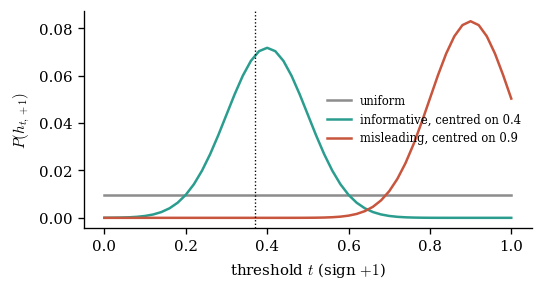

In [14]:
show_figure("tp4_priors")

In [15]:
show_table("p3_occam")

| prior | ERM – bound | ERM – true risk | bound minimizer – bound | bound minimizer – true risk | coverage (all $h$) |
|:---:|:---:|:---:|:---:|:---:|:---:|
| uniform | 0.318 | 0.163 | 0.318 | 0.163 | 0.9990 |
| informative, centred on 0.4 | 0.292 | 0.163 | 0.291 | 0.161 | 0.9985 |
| misleading, centred on 0.9 | 0.443 | 0.163 | 0.432 | 0.177 | 0.9995 |

The informative prior tightens the certificate of the ERM from $0.318$ to $0.292$. The misleading prior loosens it to $0.443$, and minimizing its bound leads to a worse classifier ($0.177$ instead of $0.163$): the bound pulls the choice towards the region favoured by the prior. In all cases the coverage is above $99.8\%$: *a bad prior never makes the bound wrong, only loose*.

**3.** No: the proof requires $P$ to be fixed before the sample is drawn (the confidence $\delta P(h)$ given to each $h$ must not depend on $S$). A prior may use any knowledge *independent of $S$*: expert knowledge, another dataset, or a part of the data that is set aside (Section 14.6). This is the key idea of PAC-Bayes: a prior over the classifiers, and a complexity term $\ln\frac{1}{P(h)}$ that measures how far the data moved us from it. The rest of the session replaces the single classifier $h$ by a *distribution* $Q$ over classifiers, and $\ln\frac1{P(h)}$ by $\operatorname{KL}(Q\|P)$.

**From one classifier to a distribution over classifiers.** We keep the toy problem and its class $\mathcal{H}$ of $K=102$ thresholds; the prior $P$ is now uniform on $\mathcal{H}$. A *posterior* is any distribution $Q$ on $\mathcal{H}$, possibly chosen using the sample $S$ of size $m$. We recall (Sections 12 and 14 of the lecture notes):

-   the **Gibbs classifier** $G_{Q}$ draws $h\sim Q$ and predicts $h(x)$; its risks are $R_{\mathcal{D}}(G_{Q})=\sum_hQ(h)R_{\mathcal{D}}(h)$ and $\widehat{R}_{S}(G_{Q})=\sum_hQ(h)\widehat{R}_{S}(h)$ (Definition 12.1); the **majority vote** $B_{Q}$ is the subject of TP 5;

-   the **KL divergence** $\operatorname{KL}(Q\|P)=\sum_hQ(h)\ln\frac{Q(h)}{P(h)}$, with $0\ln0=0$ (Definition 14.1);

-   the **PAC-Bayesian bound** of Theorem 14.4: for $\lambda>0$ *fixed before seeing $S$*, with probability at least $1-\delta$, for all $Q$ simultaneously, $$R_{\mathcal{D}}(G_{Q})\leq\widehat{R}_{S}(G_{Q})+\frac{\operatorname{KL}(Q\|P)+\ln\frac1\delta}{\lambda}+\frac{\lambda}{8m};$$

-   the bounds of **McAllester** and **Seeger** (Theorem 14.5): for $m\geq8$, with probability at least $1-\delta$, for all $Q$ simultaneously, $$\begin{gathered}
          \text{(McAllester)}\quad R_{\mathcal{D}}(G_{Q})\leq\widehat{R}_{S}(G_{Q})+\sqrt{\frac{\operatorname{KL}(Q\|P)+\ln\frac{2\sqrt m}{\delta}}{2m}},\\
          \text{(Seeger)}\quad R_{\mathcal{D}}(G_{Q})\leq\overline{\operatorname{kl}}^{-1}\Big(\widehat{R}_{S}(G_{Q}),\ \frac{\operatorname{KL}(Q\|P)+\ln\frac{2\sqrt m}{\delta}}{m}\Big).
          
    \end{gathered}$$

> **Good practice.** Work with *vectors*: a posterior is an array of $102$ nonnegative numbers summing to $1$, so that $\widehat{R}_{S}(G_{Q})$ is `Q @ r` and $R_{\mathcal{D}}(G_{Q})$ is `Q @ R`. To compute $\operatorname{KL}(Q\|P)$, sum only over the $h$ with $Q(h)>0$. To compute weights $\propto e^{a_h}$ for large $a_h$, subtract $\max_ha_h$ before taking the exponential.

## Part 4 – Posteriors, Gibbs risk and KL divergence (Sections 12.2 and 14.1)

1.  Show that, for the uniform prior, $\operatorname{KL}(Q\|P)=\ln K-H(Q)$ with $H(Q)=-\sum_hQ(h)\ln Q(h)\geq0$, so that $0\leq\operatorname{KL}(Q\|P)\leq\ln K$.\
    What is the KL of the uniform distribution on $k$ of the $K$ classifiers (Example 14.1)? Of a Dirac mass?

2.  Draw one sample of size $m=100$.\
    For the following posteriors, compute $\widehat{R}_{S}(G_{Q})$, $\operatorname{KL}(Q\|P)$ and the true Gibbs risk $R_{\mathcal{D}}(G_{Q})$: (a) the Dirac mass on the ERM $\hat h=h_{\hat t,\hat s}$; (b) the prior itself; (c) the uniform distribution on the $5$ classifiers with the smallest empirical risks; (d) the uniform distribution on the $h_{t,+1}$ with $|t-\hat t|\leq0.1$.\
    Which posterior would you like to certify? What makes it "complex"?

In [16]:
def posteriors(r):
    """The four posteriors of Part 4, built from the empirical risks r of one sample."""
    j = int(np.argmin(r)); Qs = {}
    Qs["(a) Dirac on the ERM"] = np.eye(K)[j]
    Qs["(b) uniform on $\\Hcal$ ($Q=P$)"] = PRIOR.copy()
    best5 = np.argsort(r, kind="stable")[:5]; Q = np.zeros(K); Q[best5] = 1 / 5; Qs["(c) uniform on the 5 best"] = Q
    near = (SS > 0) & (np.abs(TT - TT[j]) <= 0.1 + 1e-9); Qs["(d) uniform on $|t-\\hat t|\\leq0.1$, $s=+1$"] = near / near.sum()
    return Qs


def part4():
    print("Part 4")
    R = true_risks(); rng = np.random.RandomState(0); m = 100
    x, y = sample(m, rng); r = emp_risks(x, y); j = int(np.argmin(r))
    print(f"   ERM: t = {TT[j]:.2f}, s = {SS[j]:+.0f}, empirical risk {r[j]:.3f}, true risk {R[j]:.3f}")
    keep_table("p4_posteriors", [f"{lab} & {Q @ r:.3f} & {KL(Q, PRIOR):.2f} & {Q @ R:.3f}" for lab, Q in posteriors(r).items()])
    return x, y

In [17]:
x, y = part4()

Part 4
   ERM: t = 0.38, s = +1, empirical risk 0.110, true risk 0.157


### Solution

**1.** With $P(h)=1/K$, $\operatorname{KL}(Q\|P)=\sum_hQ(h)\ln Q(h)+\sum_hQ(h)\ln K=\ln K-H(Q)$. Since $0\leq Q(h)\leq1$, $-Q(h)\ln Q(h)\geq0$, so $H(Q)\geq0$ and $\operatorname{KL}(Q\|P)\leq\ln K$; and $\operatorname{KL}\geq0$ (Proposition 14.2, Part 8). The uniform distribution on $k$ classifiers has $H(Q)=\ln k$, hence $\operatorname{KL}(Q\|P)=\ln\frac Kk$ (Example 14.1); a Dirac mass ($k=1$) has the largest KL, $\ln K=\ln102\approx4.62$, and $\operatorname{KL}(P\|P)=0$.

**2.** On one sample of size $m=100$ (the ERM is $h_{0.38,+1}$):

In [18]:
show_table("p4_posteriors")

| posterior $Q$ | $\widehat{R}_S(G_Q)$ | $\operatorname{KL}(Q\Vert P)$ | $R_{\mathcal{D}}(G_Q)$ |
|:---:|:---:|:---:|:---:|
| (a) Dirac on the ERM | 0.110 | 4.62 | 0.157 |
| (b) uniform on $\mathcal{H}$ ($Q=P$) | 0.500 | 0.00 | 0.500 |
| (c) uniform on the 5 best | 0.128 | 3.02 | 0.168 |
| (d) uniform on $\vert t-\hat t\vert \leq0.1$, $s=+1$ | 0.153 | 2.23 | 0.189 |

We would like to certify a posterior with a small *true* Gibbs risk, but we only see its empirical Gibbs risk. The Dirac mass on the ERM has the smallest empirical risk ($0.110$), the prior the largest ($0.5$, it votes at random). What makes a posterior complex is how far it moved from the prior, i.e. how much it *concentrated* its mass after seeing the data: the KL goes from $0$ for the prior to $\ln K=4.62$ for a Dirac mass. Posteriors (c) and (d) spread their mass over several good classifiers: their empirical risk is slightly larger than that of the Dirac mass, but their complexity is smaller ($\ln\frac{102}{5}=3.02$ and $\ln\frac{102}{11}=2.23$). The bounds of Part 5 make this trade-off precise.

## Part 5 – The PAC-Bayesian bounds (Sections 14.3–14.5)

1.  On the sample of Part 4, compute the bound of Theorem 14.4 for the four posteriors and $\lambda\in\{10,30,100,300\}$.\
    Plot it as a function of $\lambda\in[1,10^4]$ for the posteriors (a) and (d).\
    Which term dominates for a small $\lambda$, for a large $\lambda$?

2.  For a fixed $Q$, show that the value of $\lambda$ that minimizes the bound is $\lambda^\star=\sqrt{8m\big(\operatorname{KL}(Q\|P)+\ln\frac1\delta\big)}$, and that the minimum is $\widehat{R}_{S}(G_{Q})+\sqrt{\big(\operatorname{KL}(Q\|P)+\ln\frac1\delta\big)/(2m)}$.\
    Why can we *not* use $\lambda^\star$, computed from the data, in Theorem 14.4?\
    Show that choosing $\lambda$ in a grid of $k$ values fixed in advance is allowed if $\ln\frac1\delta$ is replaced by $\ln\frac k\delta$, and compute this certificate for the four posteriors with the grid $\{10,30,100,300\}$.

3.  Compute McAllester's and Seeger's bounds for the four posteriors, and compare all the certificates.\
    Compare the certificate of the Dirac mass with Occam's bound for $\hat h$ (Part 3).\
    Why is the PAC-Bayesian bound a little looser here?

In [19]:
LAMBDAS = [10, 30, 100, 300]                   # grid fixed before seeing the sample


def part5(x, y):
    print("Part 5")
    R = true_risks(); m = len(y); r = emp_risks(x, y); rows, rows2 = [], []
    for lab, Q in posteriors(r).items():
        ge, kq = Q @ r, KL(Q, PRIOR)
        lin = [linear_bound(ge, kq, m, lam) for lam in LAMBDAS]
        lam_star = np.sqrt(8 * m * (kq + np.log(1 / DELTA)))
        grid = min(linear_bound(ge, kq, m, lam, DELTA / len(LAMBDAS)) for lam in LAMBDAS)
        rows.append(f"{lab} & " + " & ".join(f"{b:.3f}" for b in lin) + f" & {linear_bound(ge, kq, m, lam_star):.3f} ($\\lambda^\\star={lam_star:.0f}$) & {grid:.3f}")
        rows2.append(f"{lab} & {grid:.3f} & {mcallester(ge, kq, m):.3f} & {seeger(ge, kq, m):.3f} & {Q @ R:.3f}")
    j = int(np.argmin(r)); occ = kl_inv_upper(r[j], (np.log(K) + np.log(1 / DELTA)) / m)
    rows2.append(f"--- Occam's bound for the ERM (Part 3) & -- & -- & {occ:.3f} & {R[j]:.3f}")
    keep_table("p5_linear", rows); keep_table("p5_all", rows2)
    lams = np.logspace(0, 4, 200)
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6), sharey=True)
    for ax, lab in zip(axes, ["(a) Dirac on the ERM", "(d) uniform on $|t-\\hat t|\\leq0.1$, $s=+1$"]):
        Q = posteriors(r)[lab]; ge, kq = Q @ r, KL(Q, PRIOR)
        ax.plot(lams, linear_bound(ge, kq, m, lams), color=C1, label="Theorem 14.4")
        ax.plot(lams, ge + (kq + np.log(1 / DELTA)) / lams, color=C4, ls="--", lw=1, label=r"$\hat R_S(G_Q)+\frac{\mathrm{KL}+\ln(1/\delta)}{\lambda}$")
        ax.plot(lams, ge + lams / (8 * m), color=C5, ls=":", lw=1, label=r"$\hat R_S(G_Q)+\frac{\lambda}{8m}$")
        ax.axhline(seeger(ge, kq, m), color=C2, lw=1, label="Seeger")
        ax.axhline(Q @ R, color=C3, lw=1, label=r"true Gibbs risk $R_D(G_Q)$")
        ax.set_xscale("log"); ax.set_ylim(0, 1); ax.set_xlabel(r"$\lambda$")
        ax.set_title(lab.replace("$\\Hcal$", "H"), fontsize=8.5)
    axes[0].legend(fontsize=6.5); fig.tight_layout(); keep_figure(fig, "tp4_linear")

In [20]:
part5(x, y)

Part 5


### Solution

**1.** Bound of Theorem 14.4 for the four posteriors and four values of $\lambda$ (last columns: question 2):

In [21]:
show_table("p5_linear")

| posterior $Q$ | $\lambda=10$ | $\lambda=30$ | $\lambda=100$ | $\lambda=300$ | $\lambda^\star$ (not allowed) | best of the grid, $\ln\frac4\delta$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| (a) Dirac on the ERM | 0.885 | 0.402 | 0.311 | 0.510 | 0.305 ($\lambda^\star=78$) | 0.325 |
| (b) uniform on $\mathcal{H}$ ($Q=P$) | 0.812 | 0.637 | 0.655 | 0.885 | 0.622 ($\lambda^\star=49$) | 0.669 |
| (c) uniform on the 5 best | 0.742 | 0.366 | 0.313 | 0.523 | 0.301 ($\lambda^\star=69$) | 0.327 |
| (d) uniform on $\vert t-\hat t\vert \leq0.1$, $s=+1$ | 0.688 | 0.364 | 0.330 | 0.545 | 0.314 ($\lambda^\star=65$) | 0.344 |

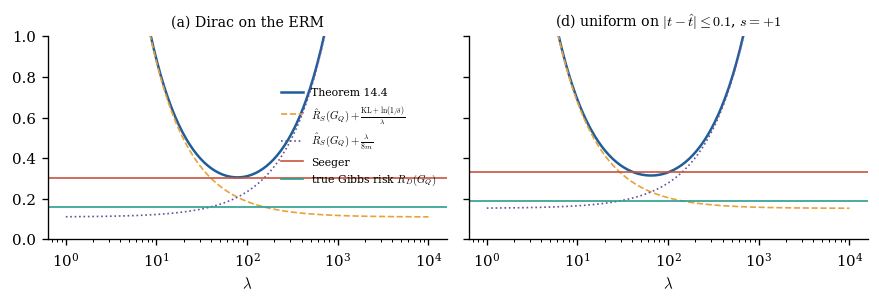

In [22]:
show_figure("tp4_linear")

For a small $\lambda$, the term $\frac{\operatorname{KL}(Q\|P)+\ln(1/\delta)}{\lambda}$ dominates (orange): the bound is vacuous for $\lambda=10$. For a large $\lambda$, the term $\frac{\lambda}{8m}$ dominates (purple): it comes from Hoeffding's lemma (step 1 of the proof) and grows linearly. In between, the bound is at its best around $\lambda\approx70$, where it is close to Seeger's bound.

**2.** The function $g(\lambda)=\frac c\lambda+\frac\lambda{8m}$, with $c=\operatorname{KL}(Q\|P)+\ln\frac1\delta$, is convex on $(0,\infty)$ and $g'(\lambda)=-\frac c{\lambda^2}+\frac1{8m}$ vanishes at $\lambda^\star=\sqrt{8mc}$, where $g(\lambda^\star)=2\sqrt{\frac c{8m}}=\sqrt{\frac c{2m}}$: the minimum of the bound is $\widehat{R}_{S}(G_{Q})+\sqrt{\frac{\operatorname{KL}(Q\|P)+\ln(1/\delta)}{2m}}$, a McAllester-type bound with $\ln\frac1\delta$ instead of $\ln\frac{2\sqrt m}\delta$. But $\lambda^\star$ depends on $\operatorname{KL}(Q\|P)$, hence on $Q$ and on the sample, while Theorem 14.4 requires $\lambda$ to be fixed *before* seeing the sample (step 2 of the proof applies Markov's inequality to $\mathbb{E}_{h\sim P}e^{\lambda\Delta(h)}$, a random variable that must not depend on the data through $\lambda$). The column $\lambda^\star$ is therefore *not* a valid certificate. Remedy: fix a grid $\lambda_1,\dots,\lambda_k$ in advance and apply the theorem to each $\lambda_j$ at level $\delta/k$. By the union bound, with probability at least $1-\delta$ the $k$ bounds hold simultaneously (for all $Q$), so we may keep the smallest one: $\ln\frac1\delta$ becomes $\ln\frac k\delta$ (last column, $k=4$: a small price, $\ln4\approx1.4$).

**3.** All the certificates, and the true Gibbs risk:

In [23]:
show_table("p5_all")

| posterior $Q$ | Theorem 14.4, grid | McAllester | Seeger | $R_{\mathcal{D}}(G_Q)$ |
|:---:|:---:|:---:|:---:|:---:|
| (a) Dirac on the ERM | 0.325 | 0.340 | 0.303 | 0.157 |
| (b) uniform on $\mathcal{H}$ ($Q=P$) | 0.669 | 0.673 | 0.668 | 0.500 |
| (c) uniform on the 5 best | 0.327 | 0.340 | 0.309 | 0.168 |
| (d) uniform on $\vert t-\hat t\vert \leq0.1$, $s=+1$ | 0.344 | 0.355 | 0.331 | 0.189 |
| Occam's bound for the ERM (Part 3) | – | – | 0.268 | 0.157 |

Seeger's bound is always the tightest, and McAllester's the loosest (Seeger's bound is never worse, by Pinsker's inequality, Section 14.4). The bound of Theorem 14.4 with the grid lies in between: it is the bound whose proof is the simplest, but it pays for the choice of $\lambda$. All the certificates are above the true Gibbs risk. Each of them balances the *empirical Gibbs risk*, small when $Q$ puts its mass on good classifiers, and the *complexity* $\operatorname{KL}(Q\|P)$, small when $Q$ stays close to the prior (Section 14.5): the uniform posterior on the $5$ best classifiers is almost as well certified as the Dirac mass, with a smaller KL.

For a Dirac mass the KL term is $\ln\frac1{P(\hat h)}$, exactly the complexity term of Occam's bound: the change of measure costs nothing here (with $\lambda^\star$, Theorem 14.4 for a Dirac mass is exactly Occam's bound in its Hoeffding form, question 2). The only difference is the confidence term of Seeger's bound, $\ln\frac{2\sqrt m}{\delta}=\ln400\approx6.0$ instead of $\ln\frac1\delta\approx3.0$: the term $\ln(2\sqrt m)$ is the small price paid for a bound that is not tied to a value of $\lambda$ fixed in advance (Section 14.4). It makes the PAC-Bayesian certificate slightly looser for a single classifier ($0.303$ against $0.268$). The interest of PAC-Bayes lies in the posteriors that are *not* Dirac masses, and in the majority votes of TP 5.

## Part 6 – The Gibbs posterior (Section 14.6)

For $\lambda>0$, the *Gibbs posterior* is $Q_\lambda(h)=\frac{P(h)\,e^{-\lambda\widehat{R}_{S}(h)}}{Z_\lambda}$ (Proposition 14.6): it minimizes $\widehat{R}_{S}(G_{Q})+\frac{\operatorname{KL}(Q\|P)}{\lambda}$, hence the bound of Theorem 14.4 for this $\lambda$.

1.  What is $Q_\lambda$ for $\lambda=0$ (where the formula still makes sense), and what is the limit of $Q_\lambda$ when $\lambda\to\infty$?

2.  On the sample of Part 4, for $\lambda\in\{0\}\cup[1,10^4]$ (logarithmic grid of $41$ values), plot $\widehat{R}_{S}(G_{Q_\lambda})$, $\operatorname{KL}(Q_\lambda\|P)/m$, Seeger's bound and $R_{\mathcal{D}}(G_{Q_\lambda})$ against $\lambda$.\
    Plot $Q_\lambda$ for a few values of $\lambda$.

3.  Select $\lambda$ by minimizing Seeger's bound.\
    Why is Seeger's bound still valid for the selected posterior, without any union bound over the grid (compare with Part 2 and with question 2 of Part 5)?

In [24]:
LAMS = np.r_[0, np.logspace(0, 4, 41)]          # grid of the Gibbs posteriors (41 positive values)


def part6(x, y):
    print("Part 6")
    R = true_risks(); m = len(y); r = emp_risks(x, y)
    out = []
    for lam in LAMS:
        Q = gibbs_posterior(r, lam); ge, kq = Q @ r, KL(Q, PRIOR)
        out.append((lam, ge, kq, seeger(ge, kq, m), Q @ R))
    out = np.array(out); i = int(np.argmin(out[:, 3]))
    rows = [f"{l:.3g} & {ge:.3f} & {kq:.2f} & {sb:.3f} & {tr:.3f}" for l, ge, kq, sb, tr in out[[0, 1, 11, 21, 25, 31, 41]]]
    rows.append(f"--- {out[i, 0]:.3g} (best) & {out[i, 1]:.3f} & {out[i, 2]:.2f} & {out[i, 3]:.3f} & {out[i, 4]:.3f}")
    keep_table("p6_gibbs", rows)
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6))
    ax = axes[0]
    ax.plot(out[1:, 0], out[1:, 1], color=C1, label=r"empirical Gibbs risk $\hat R_S(G_Q)$")
    ax.plot(out[1:, 0], out[1:, 4], color=C3, label=r"true Gibbs risk $R_D(G_Q)$")
    ax.plot(out[1:, 0], out[1:, 3], color=C2, label="Seeger's bound")
    ax.plot(out[1:, 0], out[1:, 2] / m, color=GREY, ls="--", label=r"$\mathrm{KL}(Q\|P)/m$")
    ax.axvline(out[i, 0], color="k", ls=":", lw=0.8); ax.set_xscale("log"); ax.set_xlabel(r"$\lambda$")
    ax.set_ylim(0, 0.6); ax.legend(fontsize=6.8); ax.set_title(f"$m={m}$, uniform prior", fontsize=9)
    ax = axes[1]
    for l, c in [(10, GREY), (100, C4), (out[i, 0], C2), (3000, C5)]:
        Q = gibbs_posterior(r, l)
        ax.plot(T, Q[:51], color=c, label=fr"$\lambda={l:.0f}$")
    ax.axvline(THETA, color="k", ls=":", lw=0.8)
    ax.set_xlabel("threshold $t$ (sign $+1$)"); ax.set_ylabel(r"$Q_\lambda(h_{t,+1})$"); ax.legend(fontsize=7)
    fig.tight_layout(); keep_figure(fig, "tp4_gibbs")

In [25]:
part6(x, y)

Part 6


### Solution

**1.** $Q_0=P$ (uniform). When $\lambda\to\infty$, the weights $e^{-\lambda\widehat{R}_{S}(h)}$ of the classifiers whose empirical risk is not minimal become negligible with respect to those of the minimizers: $Q_\lambda$ tends to the uniform distribution on the empirical risk minimizers (here a Dirac mass on $\hat h$). $\lambda$ interpolates between "trust the prior" and "trust the data".

**2--3.**

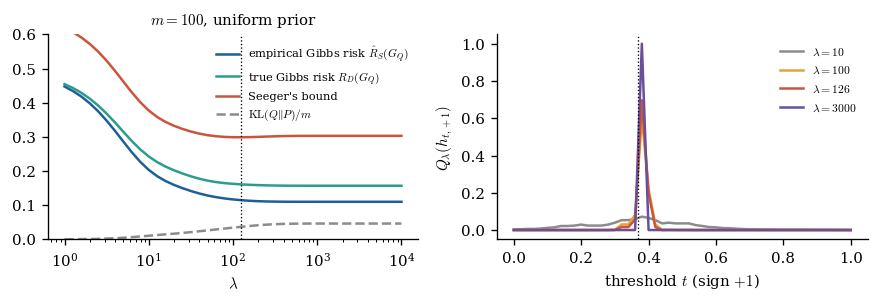

In [26]:
show_figure("tp4_gibbs")

In [27]:
show_table("p6_gibbs")

| $\lambda$ | $\widehat{R}_S(G_{Q_\lambda})$ | $\operatorname{KL}(Q_\lambda\Vert P)$ | Seeger's bound | $R_{\mathcal{D}}(G_{Q_\lambda})$ |
|:---:|:---:|:---:|:---:|:---:|
| 0 | 0.500 | 0.00 | 0.668 | 0.500 |
| 1 | 0.447 | 0.03 | 0.619 | 0.455 |
| 10 | 0.203 | 1.06 | 0.377 | 0.243 |
| 100 | 0.117 | 3.43 | 0.299 | 0.163 |
| 251 | 0.111 | 4.31 | 0.301 | 0.158 |
| 1e+03 | 0.110 | 4.62 | 0.303 | 0.157 |
| 1e+04 | 0.110 | 4.62 | 0.303 | 0.157 |
| 126 (best) | 0.115 | 3.68 | 0.299 | 0.161 |

When $\lambda$ increases, the empirical Gibbs risk decreases and the KL increases; Seeger's bound is minimal at an intermediate value ($\lambda\approx126$, bound $0.299$), slightly better than the Dirac mass ($0.303$). The selected posterior spreads its mass over the thresholds around the empirical optimum (right panel). Selecting $\lambda$ with the sample is allowed here, without any union bound: in Seeger's bound $\lambda$ is not a parameter of the bound, it only indexes the posteriors $Q_\lambda$, and the bound holds, with probability $1-\delta$, *simultaneously for all* posteriors, so it holds for any posterior chosen with the data, by any rule. This is the main practical difference with Parts 2 and 3 (a union bound over the choices) and with Theorem 14.4 (a union bound over the values of its parameter $\lambda$): the complexity of the choice of $Q$ is paid through $\operatorname{KL}(Q\|P)$.

## Part 7 – Do the bounds hold?

1.  For $m\in\{50,100,400\}$, draw $2000$ samples.\
    On each, select $\lambda$ by minimizing Seeger's bound over the grid of Part 6, and record $\widehat{R}_{S}(G_{Q_\lambda})$, $R_{\mathcal{D}}(G_{Q_\lambda})$, Seeger's bound and whether it holds; record also the bound of Theorem 14.4 for the same posterior, with the union bound over the $41$ positive values of the grid.\
    Compare with Occam's bound for the ERM and its true risk.

2.  Comment on the coverage, on the tightness of the bounds, and on the comparison with the ERM.

In [28]:
def part7():
    print("Part 7")
    R = true_risks(); rng = np.random.RandomState(1); rows = []
    lams = LAMS[1:]; k = len(lams)
    for m in [50, 100, 400]:
        res = []
        for _ in range(2000):
            x, y = sample(m, rng); r = emp_risks(x, y)
            A = np.log(PRIOR)[None, :] - lams[:, None] * r[None, :]          # all the Gibbs posteriors at once
            A -= A.max(1, keepdims=True); Q = np.exp(A); Q /= Q.sum(1, keepdims=True)
            kls = np.sum(Q * (np.log(np.maximum(Q, 1e-300)) - np.log(PRIOR)[None, :]), 1)
            sb = seeger(Q @ r, kls, m); i = int(np.argmin(sb))             # lambda chosen on the sample
            lin = linear_bound(Q[i] @ r, kls[i], m, lams[i], DELTA / k)     # union bound over the grid
            j = int(np.argmin(r)); occ = kl_inv_upper(r[j], (np.log(K) + np.log(1 / DELTA)) / m)
            g = Q[i] @ R
            res.append((Q[i] @ r, g, sb[i], g <= sb[i], lin, g <= lin, occ, R[j]))
        M = np.mean(res, 0)
        rows.append(f"{m} & {M[0]:.3f} & {M[1]:.3f} & {M[2]:.3f} & {M[3]:.4f} & {M[4]:.3f} & {M[5]:.4f} & {M[6]:.3f} & {M[7]:.3f}")
    keep_table("p7_coverage", rows)

In [29]:
part7()

Part 7


### Solution

**1.** Means over $2000$ samples ($\lambda$ selected on each sample by minimizing Seeger's bound; the bound of Theorem 14.4 is computed for the same posterior and the same $\lambda$, with $\ln\frac{41}\delta$):

In [30]:
show_table("p7_coverage")

| $m$ | $\widehat{R}_S(G_Q)$ | $R_{\mathcal{D}}(G_Q)$ | Seeger's bound | coverage | Theorem 14.4 (grid) | coverage | ERM – Occam's bound | ERM – $R_{\mathcal{D}}(\hat h)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 50 | 0.155 | 0.179 | 0.424 | 1.0000 | 0.473 | 1.0000 | 0.396 | 0.173 |
| 100 | 0.154 | 0.167 | 0.344 | 1.0000 | 0.383 | 1.0000 | 0.318 | 0.163 |
| 400 | 0.156 | 0.159 | 0.250 | 1.0000 | 0.276 | 1.0000 | 0.233 | 0.157 |

**2.** Both certificates hold on every sample (coverage $1$; the guarantee is at least $95\%$): they are worst-case statements and remain conservative. Seeger's bound is informative (about $0.25$ for $m=400$, for a true Gibbs risk of $0.16$) and decreases with $m$; the bound of Theorem 14.4, which pays for the grid of $41$ values of $\lambda$, is a little looser. On this small, finite class the Gibbs posterior does not beat Occam's bound for the ERM (the price $\ln(2\sqrt m)$ discussed in Part 5), and its true Gibbs risk is slightly larger than that of the ERM. PAC-Bayes shows its strength on large or infinite classes and on majority votes, where no union bound is possible: this is the subject of TP 5.

## Part 8 – Going further $(\star)$

1.  **The KL divergence is nonnegative.** Using Jensen's inequality for the concave function $\ln$, prove that $\operatorname{KL}(Q\|P)\geq0$, with equality if and only if $Q=P$ (Proposition 14.2).

2.  **The Gibbs posterior is optimal.** Show that, for $\lambda>0$, $\lambda\widehat{R}_{S}(G_{Q})+\operatorname{KL}(Q\|P)=\operatorname{KL}(Q\|Q_\lambda)-\ln Z_\lambda$, where $Z_\lambda=\sum_hP(h)e^{-\lambda\widehat{R}_{S}(h)}$.\
    Deduce Proposition 14.6.

3.  **Proof of Theorem 14.4.** Let $\Delta(h)=R_{\mathcal{D}}(h)-\widehat{R}_{S}(h)$.\
    (a) Using Hoeffding's lemma, $\mathbb{E}_S\big[e^{\lambda\Delta(h)}\big]\leq e^{\lambda^2/(8m)}$ for each fixed $h$, show that $\mathbb{E}_S\mathbb{E}_{h\sim P}\big[e^{\lambda\Delta(h)}\big]\leq e^{\lambda^2/(8m)}$.\
    (b) Deduce with Markov's inequality (Lemma 13.1) that, with probability at least $1-\delta$, $\mathbb{E}_{h\sim P}\big[e^{\lambda\Delta(h)}\big]\leq\frac1\delta e^{\lambda^2/(8m)}$.\
    (c) Conclude with the change of measure (Lemma 14.3), $\mathbb{E}_{h\sim Q}[\phi(h)]\leq\operatorname{KL}(Q\|P)+\ln\mathbb{E}_{h\sim P}\big[e^{\phi(h)}\big]$, applied to $\phi=\lambda\Delta$.\
    Why does the result hold for all $Q$ simultaneously, and why must $\lambda$ be fixed in advance?

### Solution

**1.** Let $\mathcal{H}_Q=\{h:Q(h)>0\}$. With $U=\frac{P(h)}{Q(h)}$ and $h\sim Q$, Jensen's inequality for the concave function $\ln$ gives $$-\operatorname{KL}(Q\|P)=\sum_{h\in\mathcal H_Q}Q(h)\ln\frac{P(h)}{Q(h)}\leq\ln\sum_{h\in\mathcal H_Q}Q(h)\frac{P(h)}{Q(h)}=\ln\sum_{h\in\mathcal H_Q}P(h)\leq\ln1=0 .$$ Equality in Jensen's inequality requires $U$ to be constant on $\mathcal H_Q$, and equality in the last step requires $P(\mathcal H_Q)=1$: together, $Q=P$.

**2.** Since $Q_\lambda(h)=P(h)e^{-\lambda\widehat{R}_{S}(h)}/Z_\lambda$, $\ln\frac{Q(h)}{P(h)}=\ln\frac{Q(h)}{Q_\lambda(h)}-\lambda\widehat{R}_{S}(h)-\ln Z_\lambda$. Multiplying by $Q(h)$ and summing over $h$: $\operatorname{KL}(Q\|P)=\operatorname{KL}(Q\|Q_\lambda)-\lambda\widehat{R}_{S}(G_{Q})-\ln Z_\lambda$, which is the claimed identity. The right-hand side is minimal when $\operatorname{KL}(Q\|Q_\lambda)=0$, i.e. $Q=Q_\lambda$ (question 1): $Q_\lambda$ minimizes $\widehat{R}_{S}(G_{Q})+\frac{\operatorname{KL}(Q\|P)}{\lambda}$, hence the bound of Theorem 14.4 for this $\lambda$ (Proposition 14.6).

**3.** (a) For each fixed $h$, the losses are i.i.d. in $[0,1]$ and Hoeffding's lemma gives $\mathbb{E}_S\big[e^{\lambda\Delta(h)}\big]\leq e^{\lambda^2/(8m)}$. Since $P$ does not depend on $S$, we can exchange the two expectations: $\mathbb{E}_S\mathbb{E}_{h\sim P}\big[e^{\lambda\Delta(h)}\big]=\mathbb{E}_{h\sim P}\mathbb{E}_S\big[e^{\lambda\Delta(h)}\big]\leq e^{\lambda^2/(8m)}$.

(b) The random variable $Z=\mathbb{E}_{h\sim P}\big[e^{\lambda\Delta(h)}\big]\geq0$ depends on $S$ only. Markov's inequality (Lemma 13.1) gives, with probability at least $1-\delta$, $Z\leq\frac{\mathbb{E}_SZ}\delta\leq\frac1\delta e^{\lambda^2/(8m)}$.

(c) On this event, for *every* $Q$, the change of measure with $\phi=\lambda\Delta$ gives $$\lambda\big(R_{\mathcal{D}}(G_{Q})-\widehat{R}_{S}(G_{Q})\big)=\mathbb{E}_{h\sim Q}[\lambda\Delta(h)]\leq\operatorname{KL}(Q\|P)+\ln Z\leq\operatorname{KL}(Q\|P)+\ln\frac1\delta+\frac{\lambda^2}{8m},$$ and dividing by $\lambda$ gives Theorem 14.4. The event of step (b) does not involve $Q$: this is why the bound holds for all $Q$ simultaneously, and why $Q$ may be chosen with the data. It does involve $\lambda$, which appears inside $Z$: if $\lambda$ were chosen with the data, $Z$ would no longer be the variable to which Markov's inequality was applied, hence the union bound over a grid fixed in advance (Part 5, question 2).